<div align="center">

# ☀️ ○○을 비춰라

### 물건을 카메라에 비춰야 꺼지는 기상 미션 알람

**YOLO11n 파인튜닝 · Open Images 13종 · 아이폰 웹앱**

ROKEY 부트캠프 딥러닝 스터디 · 2026. 11.

[▶ 앱 열기 (아이폰 Safari)](https://rltjr4362.github.io/wakeup-mission/) &nbsp;·&nbsp; [GitHub](https://github.com/rltjr4362/wakeup-mission)

</div>

---

## 요약

> **문제** &nbsp; 알람을 끄려면 *"우산을 비춰라!"* 처럼 제시된 물건을 카메라에 비춰야 한다. 내 우산이 아니라 **아무 우산이나** 통과해야 하고, **엉뚱한 물건은 통과하면 안 된다.**
>
> **방법** &nbsp; COCO로 미리 학습된 **YOLO11n**을 **Open Images**의 13종으로 파인튜닝하고, 브라우저에서 돌아가는 **웹앱**으로 만들었다.
>
> **결과** &nbsp; 실험 5개(기준선 · A · B · C · E)를 거쳐 지금 앱(v2)은 미션 통과율 **0.62 → 0.70**, "뭐든 마우스로 잡히는" 잘못 통과를 **9.2% → 0.9%** 로 바꿨다.

| | 앱 v1 (실험 A) | **앱 v2 (실험 E)** |
|:--|:--:|:--:|
| 클래스 수 | 10 | **13** (+컵 · 텀블러 · 의자) |
| 미션 통과율 (기존 10종) | 0.62 | **0.70** |
| 엉뚱한 물건이 통과한 비율 | 22.3% | **11.4%** |
| 그중 "마우스"로 통과 | 9.2% | **0.9%** |

<sub>통과율은 Open Images 검증 사진을 앱 화면처럼 잘라서 잰 값 (기준 0.5). 실제 폰 카메라 테스트는 아직 없다.</sub>

---

## 목차

1. [무엇을 만드나](#1.-무엇을-만드나)
2. [어떤 방법이 있었고, 왜 이걸 골랐나](#2.-어떤-방법이-있었고,-왜-이걸-골랐나)
3. [데이터](#3.-데이터)
4. [EDA — 데이터 들여다보기](#4.-EDA-—-데이터-들여다보기)
5. [원리 — YOLO는 어떻게 판단하나](#5.-원리-—-YOLO는-어떻게-판단하나)
6. [전체 파이프라인](#6.-전체-파이프라인)
7. [실험 — 왜 이 순서로 했나](#7.-실험-—-왜-이-순서로-했나)
8. [앱으로 만들기](#8.-앱으로-만들기)
9. [결론 · 한계 · 다음 할 일](#9.-결론-·-한계-·-다음-할-일)
10. [토론 질문](#10.-토론-질문)

<sub>코드 셀은 접혀 있다. 펼치면 그림·표를 만든 코드가 보인다. 학습은 다시 하지 않고 저장된 결과(`runs/`, `data/`)를 불러온다.<br>
자세한 과정: `wakeup_mission.ipynb`(A·B) · `wakeup_eda.ipynb`(EDA) · `wakeup_clean.ipynb`(C) · `wakeup_v2.ipynb`(E)</sub>

In [1]:
from pathlib import Path
import json, re, sys, warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import cv2
from IPython.display import display

warnings.filterwarnings('ignore'); logging.getLogger('matplotlib').setLevel(logging.ERROR)
plt.rcParams.update({'font.family': 'AppleGothic', 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.width', 160)

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config as C
from src.postprocess import decode, nms, pick_main

KO = [c.ko for c in C.CLASSES13]
DATA, RUNS = ROOT / 'data/yolo13_full', ROOT / 'runs'
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)

# 색: 단계별
COL = dict(data='#4C78A8', prep='#72B7B2', train='#F58518', eval='#E45756', app='#54A24B', gray='#9D9D9D')

def box(ax, x, y, w, h, title, lines=(), color='#4C78A8', fs=12):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08',
                                fc=color, ec='none', alpha=0.13))
    ax.add_patch(FancyBboxPatch((x, y + h - 0.42), w, 0.42, boxstyle='round,pad=0.02,rounding_size=0.08',
                                fc=color, ec='none'))
    ax.text(x + w / 2, y + h - 0.21, title, ha='center', va='center', color='white', fontsize=fs, weight='bold')
    for i, l in enumerate(lines):
        ax.text(x + 0.12, y + h - 0.7 - i * 0.33, l, ha='left', va='center', fontsize=fs - 2.5, color='#222')

def arrow(ax, x1, y1, x2, y2, color='#555'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='-|>', color=color, lw=1.8, mutation_scale=16))

def canvas(w, h):
    fig, ax = plt.subplots(figsize=(w, h)); ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis('off'); return fig, ax

---

## 1. 무엇을 만드나

> 💡 **한 줄** — 일어나서 물건을 찾으러 움직이게 만드는 알람. 핵심은 **"아무 물건이나 통과, 엉뚱한 물건은 거절"**.

### 1.1 요구사항

| # | 요구사항 | 기술적으로 뜻하는 것 |
|:-:|:--|:--|
| R1 | **아무 컵이나** 통과 | 처음 보는 물건도 알아보는 *일반화* 모델 |
| R2 | **아이폰에서 실시간** | 작고 빠른 모델, 서버 없이 폰에서 추론 |
| R3 | **엉뚱한 물건은 거절** | "아무것도 아님"을 말할 수 있어야 함 |
| R4 | **QR 스캐너처럼** 가운데 틀에 대면 판정 | 물체의 *위치와 크기*를 알아야 함 |

### 1.2 미션 13종

In [2]:
df = pd.DataFrame([dict(미션=C.mission_text(c),
                        출처_라벨=', '.join(c.oi_labels),
                        언제=('COCO가 원래 앎' if c.coco_id is not None else ('v1에서 새로' if c.id < 10 else 'v2에서 새로')))
                   for c in C.CLASSES13])
df.index.name = 'id'
df.style.hide(axis='index').set_properties(**{'text-align': 'left'})

미션,출처_라벨,언제
🖱️ 마우스를 비춰라,Computer mouse,COCO가 원래 앎
☂️ 우산을 비춰라,Umbrella,COCO가 원래 앎
📖 책을 비춰라,Book,COCO가 원래 앎
🪥 칫솔을 비춰라,Toothbrush,COCO가 원래 앎
🧢 모자를 비춰라,"Hat, Fedora, Sun hat, Cowboy hat, Sombrero",v1에서 새로
🚪 문을 비춰라,Door,v1에서 새로
🧻 휴지를 비춰라,Toilet paper,v1에서 새로
🧦 양말을 비춰라,Sock,v1에서 새로
👟 신발을 비춰라,"Footwear, Boot, High heels, Sandal",v1에서 새로
👓 안경을 비춰라,"Glasses, Sunglasses",v1에서 새로


### 1.3 쟁점 ① — "잘 된다"를 무엇으로 잴까?

| 지표 | 장점 | 한계 |
|:--|:--|:--|
| **mAP50** (탐지 표준) | 표준이라 비교가 쉬움 | 사진 구석의 작은 물체까지 찾아야 점수 — 앱은 **가운데 큰 물체 하나**만 보면 됨 |
| **미션 통과율** (직접 정의) | 앱 판정 규칙 그대로 → 사용자 경험과 직결 | 남과 비교할 수 없음 |
| **잘못 통과율** (직접 정의) | R3을 직접 잼 | "엉뚱한 물건" 사진이 따로 필요 |

> 📌 처음엔 mAP50만 봤다. 실험 C에서 *"mAP는 떨어졌는데 앱에선?"* 이 궁금해져 **통과율**을, 실험 E에서 *"뭐든 마우스"* 문제가 나와 **잘못 통과율**을 더했다. 지표도 문제를 겪으며 바뀌었다.

---

## 2. 어떤 방법이 있었고, 왜 이걸 골랐나

> 💡 **한 줄** — 위치를 아는 **탐지 모델(YOLO)** 하나로, 폰 안에서 돌린다.

### 2.1 후보 비교

| 방법 | 어떻게 | 👍 | 👎 | |
|:--|:--|:--|:--|:-:|
| **이미지 분류**<br><sub>ResNet, MobileNet</sub> | 화면 전체 → 클래스 하나 | 가장 단순 | 빈 벽에도 **억지로 하나를 고름**(softmax)<br>위치를 몰라 스캔 틀 규칙 불가 (R3·R4 ✗) | ✗ |
| **객체 탐지**<br><sub>YOLO11n</sub> | 박스 + 클래스 + 점수 | 위치·크기를 앎 (R4)<br>클래스별 sigmoid → "없음" 가능 (R3)<br>작아서 폰 실시간 (R2) | 박스 라벨 데이터 필요 | ✅ |
| **2단계**<br><sub>YOLO → ResNet</sub> | YOLO가 자른 영역을 분류기가 재판정 | 분류 정확도↑ 가능 | 모델 2개 → 폰에서 2배 느림, 배포도 2번 | ✗ |
| **제로샷**<br><sub>YOLO-World, CLIP</sub> | "a cup" 같은 글로 찾음 | 학습 없이 클래스 추가 | 크고 느림 (R2 ✗)<br>파인튜닝을 배우는 스터디 취지와 안 맞음 | ✗ |
| **클라우드 API**<br><sub>GPT-4o 등</sub> | 사진을 서버로 보내 물어봄 | 정확도 최고 | 매 프레임 비용·지연, 잠옷 차림 사진이 서버로 | ✗ |

### 2.2 왜 YOLO11**n** 인가

- **크기** — 파라미터 약 260만, ONNX 10.5MB. 아이폰 Safari에서 돌릴 수 있는 크기. (s·m은 더 정확하지만 폰 웹에서 프레임이 끊긴다)
- **전이학습** — COCO 80종으로 미리 학습돼 "물체를 보는 눈"이 이미 있다. 우리 클래스만 가르치면 된다.

> ❓ *"YOLO만으로 되나? ResNet을 붙여야 하나?"* → 먼저 YOLO 단독으로 해 보고, 부족하면 2단계를 비교 실험으로 붙이기로 했다. 결과적으로 단독으로 충분했다.

---

## 3. 데이터

> 💡 **한 줄** — 모자 · 문 · 양말 · 휴지까지 **박스 라벨이 있는** 공개 데이터는 Open Images뿐이었다.

### 3.1 후보 비교

| 데이터 | 👍 | 👎 | |
|:--|:--|:--|:-:|
| 직접 촬영 | 앱 상황과 똑같음 | 클래스당 수백 장 + 박스 그리기 → 불가능<br>"내 물건"만 배움 (R1 ✗) | 최종 확인용 |
| **COCO** | YOLO가 원래 배운 데이터 | 모자 · 문 · 휴지 · 양말 · 신발 · 안경이 **없음** | ✗ |
| ImageNet | 클래스가 많음 | 분류용 — 박스가 거의 없음 | ✗ |
| **Open Images V7** | 박스 있는 **600종**, 필요한 클래스 전부 있음<br>FiftyOne으로 클래스만 골라 받기 | 라벨이 지저분함 (아래) | ✅ |

### 3.2 Open Images를 쓰며 내린 결정

| 상황 | 결정 |
|:--|:--|
| 라벨이 **계층 구조** (모자 ⊃ 페도라 · 솜브레로, 신발 ⊃ 부츠 · 샌들) | 하위 라벨을 상위 클래스로 합침 |
| 같은 물체에 상위 · 하위 박스가 **둘 다** 있음 | 같은 클래스끼리 IoU ≥ 0.7이면 하나만 남김 |
| 사진마다 "확인한 클래스"만 박스를 그림 → **빠진 라벨** | 모델이 그걸 배경으로 배우는 한계로 인정 |
| 속성 CSV의 `-1(모름)`을 FiftyOne이 `True`로 읽음 | 직접 확인해서 고침 (칫솔 49개 · 양말 98개를 버릴 뻔) |

> ⚠️ **교훈** — 데이터는 **열어 봐야** 안다. 라이브러리가 읽어 준 값도 의심하기.

---

## 4. EDA — 데이터 들여다보기

> 💡 **한 줄** — 성능이 낮은 이유는 **양(불균형)이 아니라 질(어떤 장면의 라벨인가)** 이었다.

학습에 쓴 전체 사진 세트(`data/yolo13_full`)의 YOLO 라벨을 직접 읽는다. 라벨이 빈 사진은 **네거티브 사진**(휴대폰 · 리모컨 · 손처럼 미션이 아닌 물건)이다.

In [3]:
def read_labels(split):
    rows, empty = [], 0
    for f in sorted((DATA / 'labels' / split).glob('*.txt')):
        lines = [l.split() for l in f.read_text().splitlines() if l.strip()]
        empty += not lines
        rows += [dict(image=f.stem, cls=int(l[0]), 클래스=KO[int(l[0])], cx=float(l[1]), cy=float(l[2]),
                      w=float(l[3]), h=float(l[4])) for l in lines]
    df = pd.DataFrame(rows); df['area'] = df.w * df.h
    return df, empty

tr, tr_empty = read_labels('train'); va, va_empty = read_labels('val')
pd.DataFrame({'사진': [tr.image.nunique() + tr_empty, va.image.nunique() + va_empty],
              '그중 네거티브 사진': [tr_empty, va_empty], '박스': [len(tr), len(va)]},
             index=['train', 'val']).style.format('{:,}')

,사진,그중 네거티브 사진,박스
train,"7,435","1,274","20,432"
val,658,0,"1,871"


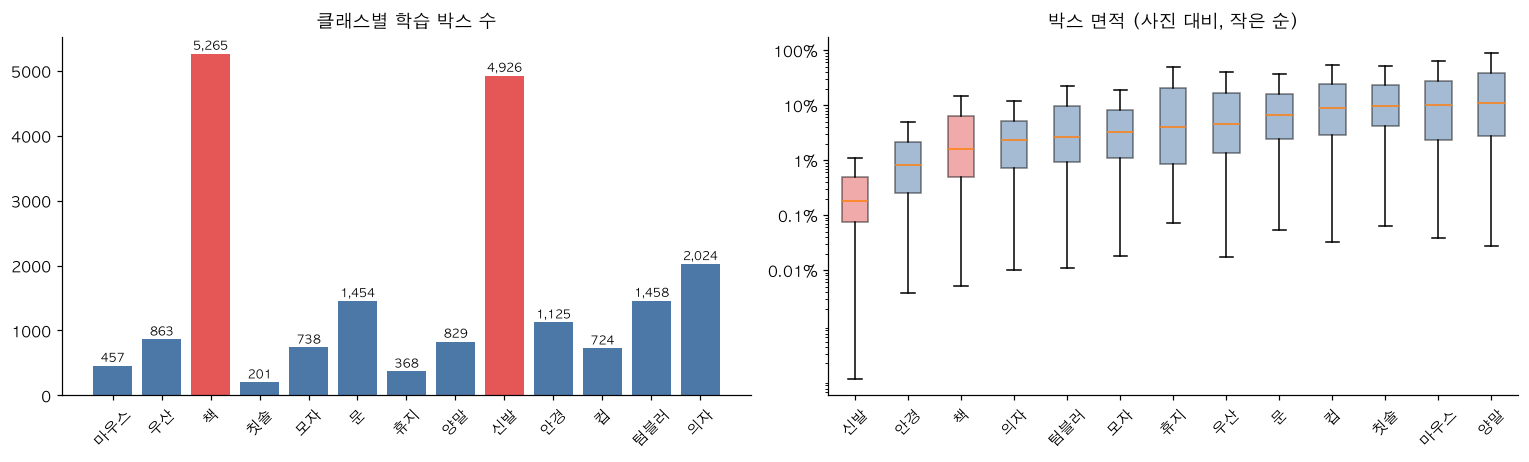

In [4]:
cnt = tr.groupby('클래스').size().reindex(KO)
order = tr.groupby('클래스').area.median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
colors = [COL['eval'] if k in ('책', '신발') else COL['data'] for k in cnt.index]
ax[0].bar(cnt.index, cnt.values, color=colors); ax[0].set_title('클래스별 학습 박스 수', weight='bold')
ax[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(cnt.values): ax[0].text(i, v + 60, f'{v:,}', ha='center', fontsize=8)
bp = ax[1].boxplot([tr[tr['클래스'] == k].area for k in order], showfliers=False, patch_artist=True)
for p, k in zip(bp['boxes'], order): p.set_facecolor(COL['eval'] if k in ('책', '신발') else COL['data']); p.set_alpha(.5)
ax[1].set_xticks(range(1, len(order) + 1), order, rotation=45)
ax[1].set_yscale('log'); ax[1].set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1], ['0.01%', '0.1%', '1%', '10%', '100%'])
ax[1].set_title('박스 면적 (사진 대비, 작은 순)', weight='bold')
plt.tight_layout(); plt.show()

<sub>빨간색 = 박스가 가장 많은 두 클래스(책 · 신발). 신발은 박스가 많지만 **가장 작다**.</sub>

### 4.1 클래스마다 한 장

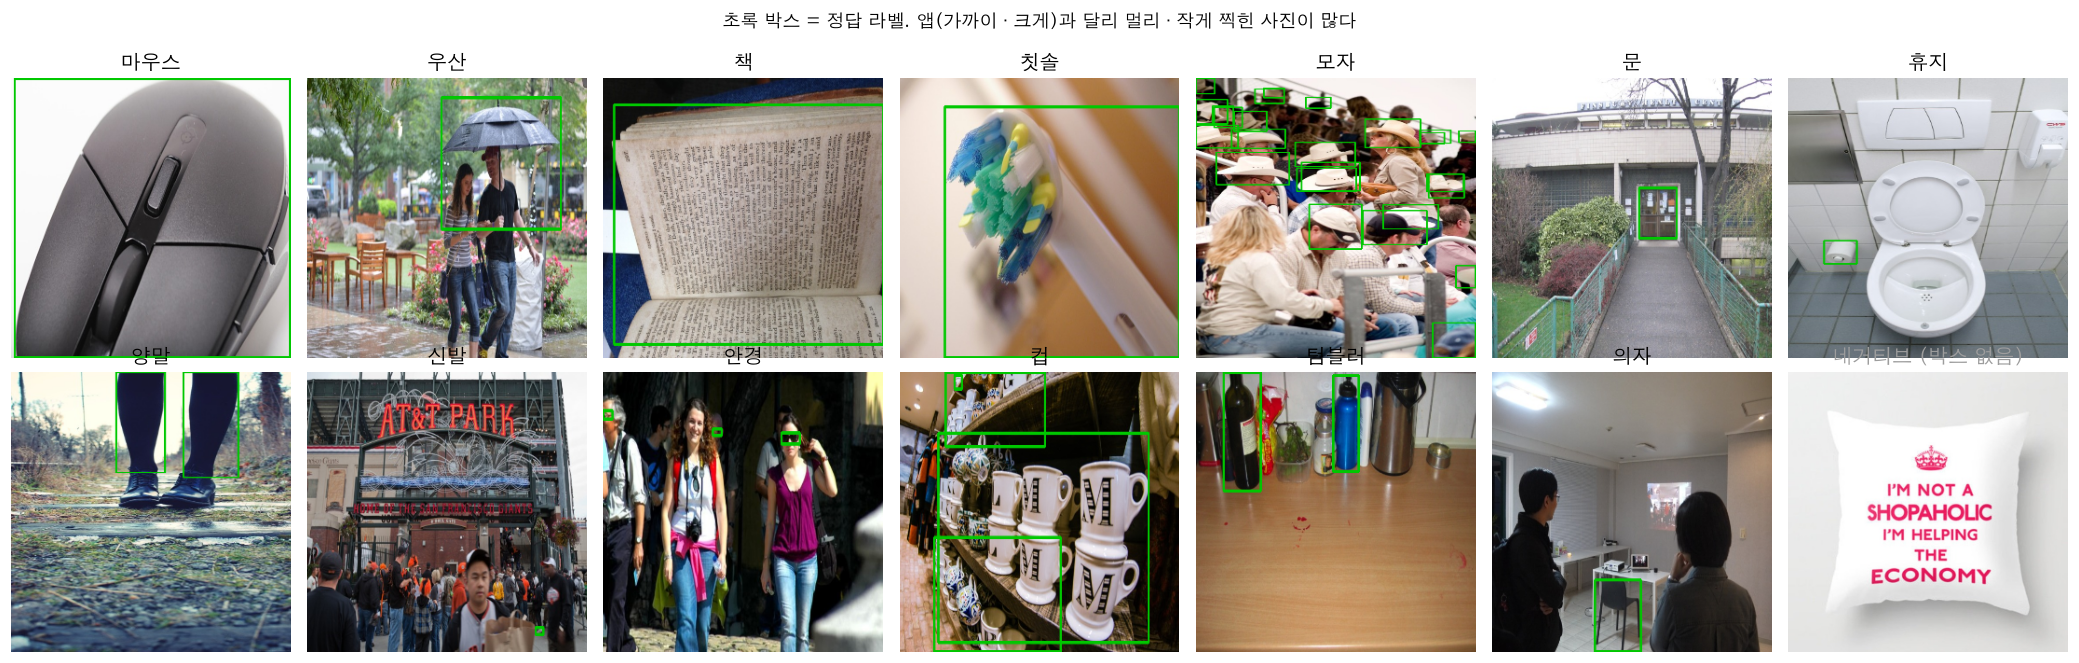

In [5]:
def draw(img_path, rows):
    img = cv2.imread(str(img_path)); H, W = img.shape[:2]
    for r in rows.itertuples():
        cv2.rectangle(img, (int((r.cx - r.w / 2) * W), int((r.cy - r.h / 2) * H)),
                      (int((r.cx + r.w / 2) * W), int((r.cy + r.h / 2) * H)), (0, 200, 0), max(2, W // 200))
    return cv2.resize(img, (300, 300))[:, :, ::-1]

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 7, figsize=(19, 6)); axes = axes.ravel()
for c in range(13):
    stem = rng.choice(tr[tr.cls == c].image.unique())
    axes[c].imshow(draw(DATA / 'images/train' / f'{stem}.jpg', tr[(tr.image == stem) & (tr.cls == c)]))
    axes[c].set_title(KO[c], fontsize=13, weight='bold')
neg = [p for p in (DATA / 'labels/train').glob('*.txt') if not p.read_text().strip()]
axes[13].imshow(cv2.resize(cv2.imread(str(DATA / 'images/train' / f'{rng.choice(neg).stem}.jpg')), (300, 300))[:, :, ::-1])
axes[13].set_title('네거티브 (박스 없음)', fontsize=13, weight='bold', color=COL['gray'])
for a in axes: a.axis('off')
plt.suptitle('초록 박스 = 정답 라벨. 앱(가까이 · 크게)과 달리 멀리 · 작게 찍힌 사진이 많다', y=1.0); plt.tight_layout(); plt.show()

### 4.2 쟁점 ② — 불균형 때문에 성능이 낮았나?

v1(실험 A) 클래스별 성능과 라벨 품질을 나란히 놓으면 (`wakeup_eda.ipynb`):

| 클래스 | A mAP50 | 박스 면적 중앙값 | 묶음 박스 | 작은 박스 (<1%) | 원인 |
|:--|:-:|:-:|:-:|:-:|:--|
| 📖 책 | **0.33** | 1.7% | **60.5%** | 37.6% | 책장 전체를 박스 하나로 |
| 🚪 문 | **0.36** | 6.1% | 0.2% | 13.0% | 대부분 **건물 외벽**의 문 |
| 👟 신발 | **0.42** | **0.3%** | 1.8% | **74.4%** | 사람 전신 사진의 발 |
| 🧦 양말 | 0.51 | 7.7% | 11.3% | 13.6% | 신발과 같이 나옴 |
| 🖱️ 마우스 | 0.87 | 10.7% | 0.2% | 9.7% | 책상 위 마우스 하나 — 깨끗 |

> 📌 **박스가 가장 많은 책 · 신발이 가장 못했다.** 문제는 양이 아니라 **질**.
> → "가중치 · 오버샘플링으로 불균형 맞추기" 대신 **데이터 정제(실험 C)** 와 **앱 장면으로 잘라 학습(실험 E)** 을 시도했다.

---

## 5. 원리 — YOLO는 어떻게 판단하나

> 💡 **한 줄** — 2,100칸마다 박스와 13개 클래스 점수를 내고, 후처리로 "주인공" 하나를 고른다.

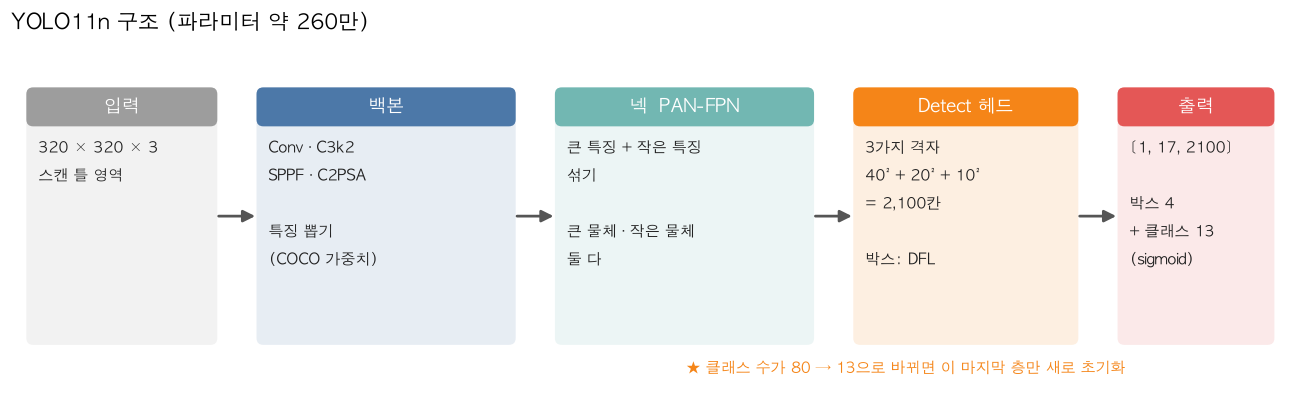

In [6]:
fig, ax = canvas(15, 4.2)
box(ax, 0.2, 0.6, 2.2, 3.0, '입력', ['320 × 320 × 3', '스캔 틀 영역'], COL['gray'])
box(ax, 2.9, 0.6, 3.0, 3.0, '백본', ['Conv · C3k2', 'SPPF · C2PSA', '', '특징 뽑기', '(COCO 가중치)'], COL['data'])
box(ax, 6.4, 0.6, 3.0, 3.0, '넥  PAN-FPN', ['큰 특징 + 작은 특징', '섞기', '', '큰 물체 · 작은 물체', '둘 다'], COL['prep'])
box(ax, 9.9, 0.6, 2.6, 3.0, 'Detect 헤드', ['3가지 격자', '40² + 20² + 10²', '= 2,100칸', '', '박스: DFL'], COL['train'])
box(ax, 13.0, 0.6, 1.8, 3.0, '출력', ['[1, 17, 2100]', '', '박스 4', '+ 클래스 13', '(sigmoid)'], COL['eval'])
for x1, x2 in [(2.4, 2.9), (5.9, 6.4), (9.4, 9.9), (12.5, 13.0)]: arrow(ax, x1, 2.1, x2, 2.1)
ax.text(10.5, 0.25, '★ 클래스 수가 80 → 13으로 바뀌면 이 마지막 층만 새로 초기화', fontsize=10, color=COL['train'], ha='center')
ax.set_title('YOLO11n 구조 (파라미터 약 260만)', fontsize=14, weight='bold', loc='left'); plt.show()
fig.savefig(FIG / 'yolo_arch.png', bbox_inches='tight')

### 5.1 전이학습 — 무엇이 새로 시작되나

- 백본 · 넥 · 박스 갈래는 **COCO 가중치 그대로** 시작, 클래스 갈래 마지막 층만 새로 초기화.
- 그래서 *"새 클래스만 학습시켜 원래 4종을 잊는지 보기"* 는 성립하지 않는다 — 클래스 층이 새로 생기므로 원래 4종은 **잊은 게 아니라 배운 적이 없는 것.** → 실험 B를 **백본 고정(freeze)** 실험으로 바꾼 이유.

### 5.2 softmax vs sigmoid — "아무것도 없음"을 말할 수 있나

빈 벽을 봤을 때, 세 클래스 점수(logit)가 모두 낮다고 하자.

In [7]:
logits = np.array([-3.0, -2.5, -3.2])
pd.DataFrame({'logit': logits,
              'softmax (분류기)': np.exp(logits) / np.exp(logits).sum(),
              'sigmoid (YOLO)': 1 / (1 + np.exp(-logits))},
             index=['마우스', '컵', '책']).style.format('{:.3f}').background_gradient(cmap='Reds', vmin=0, vmax=1, subset=['softmax (분류기)', 'sigmoid (YOLO)'])

,logit,softmax (분류기),sigmoid (YOLO)
마우스,-3.000,0.288,0.047
컵,-2.500,0.475,0.076
책,-3.200,0.236,0.039


> 📌 softmax는 합이 1이라 빈 벽에도 **"컵 47%"**. sigmoid는 클래스마다 독립이라 **모두 8% 미만 → 통과 없음.**
> 대신 sigmoid는 **기준값(conf)** 을 정해야 하고, 이 기준을 **클래스마다 다르게** 고른 것이 실험 E의 핵심 중 하나다.

### 5.3 지표

| 지표 | 뜻 |
|:--|:--|
| Precision | 모델이 "컵"이라 한 것 중 진짜 컵 비율 |
| Recall | 진짜 컵 중 모델이 찾은 비율 |
| F1 | P와 R의 조화평균 |
| mAP50 | 정답과 50% 이상 겹치면 맞음으로 보고, 기준을 바꿔 가며 그린 P-R 곡선 아래 넓이의 클래스 평균 |
| **미션 통과율** | 물건 사진을 앱 규칙으로 판정해 **목표 클래스가 나온 비율** |
| **잘못 통과율** | 엉뚱한 물건(네거티브) 사진이 **어떤 미션으로든** 통과된 비율 |

---

## 6. 전체 파이프라인

> 💡 **한 줄** — 공개 데이터를 **앱 장면처럼** 가공해 학습하고, **앱과 같은 규칙**으로 평가한 뒤, 폰 브라우저로 보낸다.

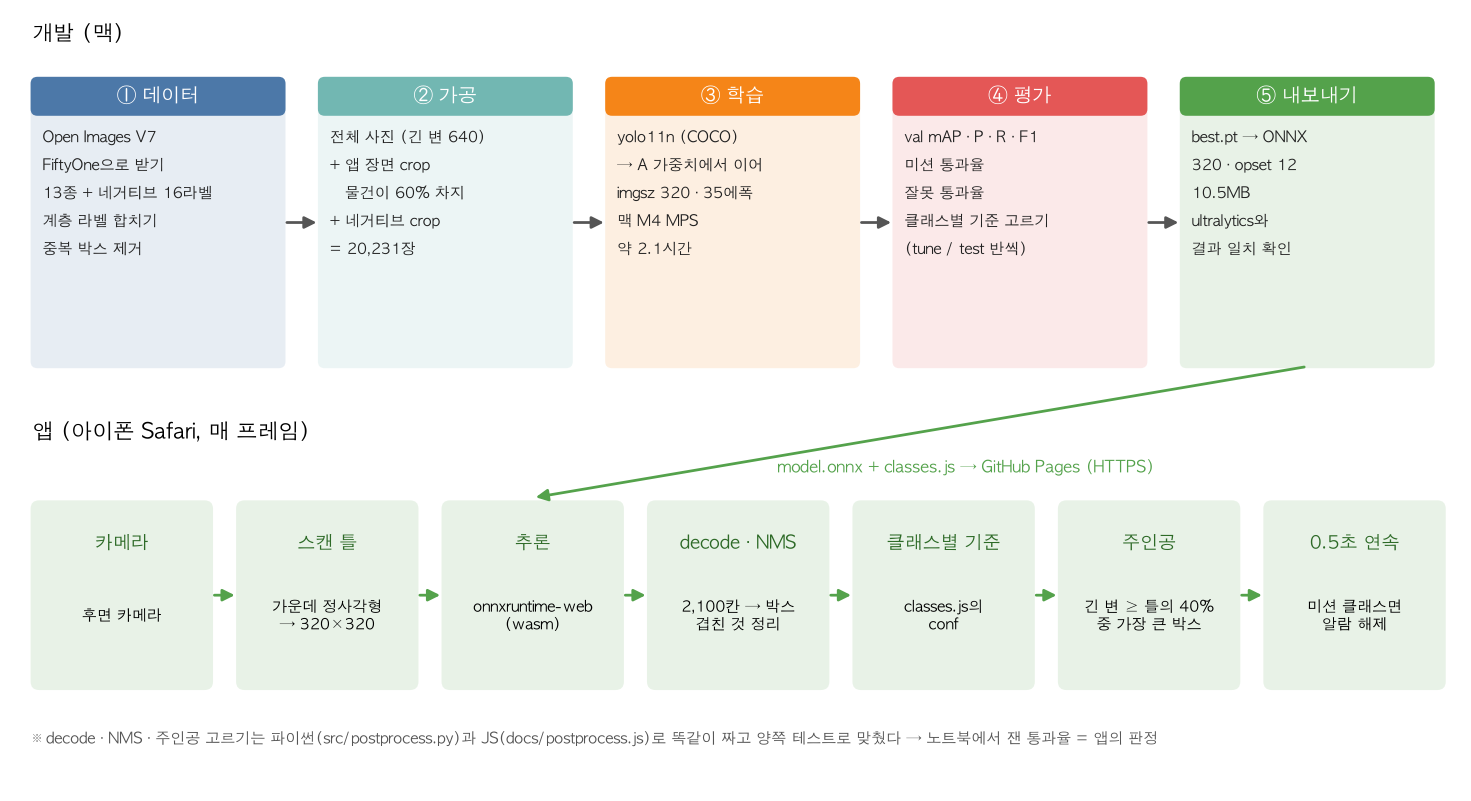

In [8]:
fig, ax = canvas(17, 9.2)
# 위: 개발 파이프라인
stages = [
    ('① 데이터', COL['data'], ['Open Images V7', 'FiftyOne으로 받기', '13종 + 네거티브 16라벨', '계층 라벨 합치기', '중복 박스 제거']),
    ('② 가공', COL['prep'], ['전체 사진 (긴 변 640)', '+ 앱 장면 crop', '   물건이 60% 차지', '+ 네거티브 crop', '= 20,231장']),
    ('③ 학습', COL['train'], ['yolo11n (COCO)', '→ A 가중치에서 이어', 'imgsz 320 · 35에폭', '맥 M4 MPS', '약 2.1시간']),
    ('④ 평가', COL['eval'], ['val mAP · P · R · F1', '미션 통과율', '잘못 통과율', '클래스별 기준 고르기', '(tune / test 반씩)']),
    ('⑤ 내보내기', COL['app'], ['best.pt → ONNX', '320 · opset 12', '10.5MB', 'ultralytics와', '결과 일치 확인']),
]
w, gap, y0 = 2.95, 0.42, 5.0
for i, (t, c, ls) in enumerate(stages):
    x = 0.25 + i * (w + gap); box(ax, x, y0, w, 3.4, t, ls, c, fs=12.5)
    if i: arrow(ax, x - gap, y0 + 1.7, x, y0 + 1.7)
ax.text(0.25, 8.85, '개발 (맥)', fontsize=14, weight='bold')
# 아래: 앱 런타임
ax.text(0.25, 4.15, '앱 (아이폰 Safari, 매 프레임)', fontsize=14, weight='bold')
steps = [('카메라', '후면 카메라'), ('스캔 틀', '가운데 정사각형\n→ 320×320'), ('추론', 'onnxruntime-web\n(wasm)'),
         ('decode · NMS', '2,100칸 → 박스\n겹친 것 정리'), ('클래스별 기준', 'classes.js의\nconf'),
         ('주인공', '긴 변 ≥ 틀의 40%\n중 가장 큰 박스'), ('0.5초 연속', '미션 클래스면\n알람 해제')]
sw, sg = 2.1, 0.31
for i, (t, d) in enumerate(steps):
    x = 0.25 + i * (sw + sg)
    ax.add_patch(FancyBboxPatch((x, 1.2), sw, 2.2, boxstyle='round,pad=0.02,rounding_size=0.1', fc=COL['app'], alpha=.13, ec='none'))
    ax.text(x + sw / 2, 2.85, t, ha='center', fontsize=12, weight='bold', color='#2d6a27')
    ax.text(x + sw / 2, 2.05, d, ha='center', va='center', fontsize=9.5)
    if i: arrow(ax, x - sg, 2.3, x, 2.3, COL['app'])
arrow(ax, 0.25 + 4 * (w + gap) + w / 2, y0, 0.25 + 2 * (sw + sg) + sw / 2, 3.45, COL['app'])
ax.text(11.2, 3.75, 'model.onnx + classes.js → GitHub Pages (HTTPS)', fontsize=10.5, color=COL['app'], ha='center', weight='bold')
ax.text(0.25, 0.55, '※ decode · NMS · 주인공 고르기는 파이썬(src/postprocess.py)과 JS(docs/postprocess.js)로 똑같이 짜고 양쪽 테스트로 맞췄다 → 노트북에서 잰 통과율 = 앱의 판정',
        fontsize=10, color='#555')
plt.show(); fig.savefig(FIG / 'pipeline.png', bbox_inches='tight')

### 6.1 실제 앱 모델로 한 장 처리해 보기

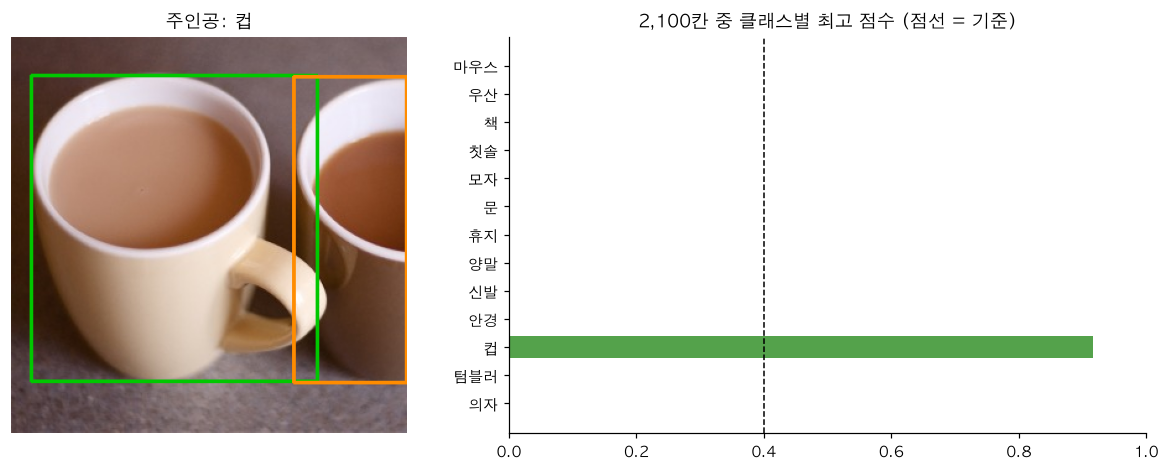

출력 (1, 17, 2100) → 기준 넘은 칸 20개 → NMS · 클래스별 기준 뒤 박스 2개 → 주인공 1개


In [9]:
import onnxruntime as ort
sess = ort.InferenceSession(str(ROOT / 'docs/model.onnx'))
cls_js = (ROOT / 'docs/classes.js').read_text()
app_conf = {c['id']: c['conf'] for c in json.loads(re.search(r'export const CLASSES = (\[.*?\]);', cls_js, re.S).group(1))}

def run_app(img_bgr):
    # 앱과 같은 순서: 320 → RGB 0~1 → 추론 → decode(가장 낮은 기준) → NMS → 클래스별 기준 → 주인공
    x = cv2.resize(img_bgr, (320, 320), interpolation=cv2.INTER_AREA)[:, :, ::-1].astype(np.float32) / 255
    out = sess.run(None, {sess.get_inputs()[0].name: x.transpose(2, 0, 1)[None].copy()})[0]
    dets = [d for d in nms(decode(out, min(app_conf.values()), 320), 0.45) if d['score'] >= app_conf[d['cls']]]
    return out, dets, pick_main(dets, 320, 0.4)

pos = pd.read_csv(ROOT / 'data/eval13/pos_crops.csv')
neg = pd.read_csv(ROOT / 'data/eval13/neg_crops.csv'); neg = neg[neg.n_rows == 0]   # 목표 물건이 40% 이상 보이는 것은 제외
for r in pos[(pos.target == 10) & (pos.half == 'test')].itertuples():   # 컵 사진 중 맞게 판정한 첫 장
    img = cv2.imread(str(ROOT / 'data/eval13/images/pos' / r.file))
    out, dets, main = run_app(img)
    if main and main['cls'] == 10 and len(dets) > 1: break
n_cand = int((out[0, 4:].max(0) >= min(app_conf.values())).sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1, 1.4]))
show = cv2.resize(img, (320, 320))
for d in dets:
    cv2.rectangle(show, (int(d['x1']), int(d['y1'])), (int(d['x2']), int(d['y2'])), (0, 200, 0) if d is main else (0, 140, 255), 2)
ax[0].imshow(show[:, :, ::-1]); ax[0].axis('off'); ax[0].set_title(f"주인공: {KO[main['cls']] if main else '없음'}", weight='bold')
best = out[0, 4:].max(1)
ax[1].barh(KO[::-1], best[::-1], color=[COL['app'] if main and i == main['cls'] else COL['gray'] for i in range(12, -1, -1)])
ax[1].axvline(0.4, ls='--', c='k', lw=1); ax[1].set_xlim(0, 1); ax[1].set_title('2,100칸 중 클래스별 최고 점수 (점선 = 기준)', weight='bold')
plt.tight_layout(); plt.show()
print(f'출력 {out.shape} → 기준 넘은 칸 {n_cand}개 → NMS · 클래스별 기준 뒤 박스 {len(dets)}개 → 주인공 1개')

---

## 7. 실험 — 왜 이 순서로 했나

> 💡 **한 줄** — 실험마다 **질문 하나**를 세우고, 결과가 다음 질문을 만들었다.

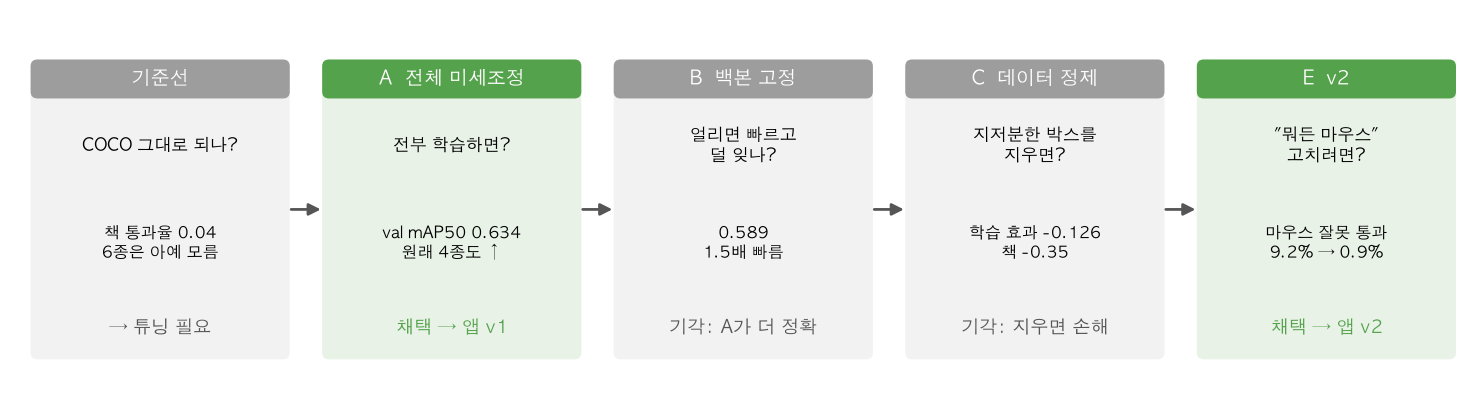

In [10]:
fig, ax = canvas(17, 4.6)
exps = [('기준선', 'COCO 그대로 되나?', '책 통과율 0.04\n6종은 아예 모름', '→ 튜닝 필요', COL['gray']),
        ('A  전체 미세조정', '전부 학습하면?', 'val mAP50 0.634\n원래 4종도 ↑', '채택 → 앱 v1', COL['app']),
        ('B  백본 고정', '얼리면 빠르고\n덜 잊나?', '0.589\n1.5배 빠름', '기각: A가 더 정확', COL['gray']),
        ('C  데이터 정제', '지저분한 박스를\n지우면?', '학습 효과 -0.126\n책 -0.35', '기각: 지우면 손해', COL['gray']),
        ('E  v2', '"뭐든 마우스"\n고치려면?', '마우스 잘못 통과\n9.2% → 0.9%', '채택 → 앱 v2', COL['app'])]
w, gap = 3.0, 0.42
for i, (t, q, r, d, c) in enumerate(exps):
    x = 0.25 + i * (w + gap)
    box(ax, x, 0.5, w, 3.5, t, [], c, fs=12.5)
    ax.text(x + w / 2, 3.0, q, ha='center', va='center', fontsize=11, style='italic')
    ax.text(x + w / 2, 1.85, r, ha='center', va='center', fontsize=10.5)
    ax.text(x + w / 2, 0.85, d, ha='center', va='center', fontsize=11.5, weight='bold', color=c if c != COL['gray'] else '#555')
    if i: arrow(ax, x - gap, 2.25, x, 2.25)
plt.show(); fig.savefig(FIG / 'experiments.png', bbox_inches='tight')

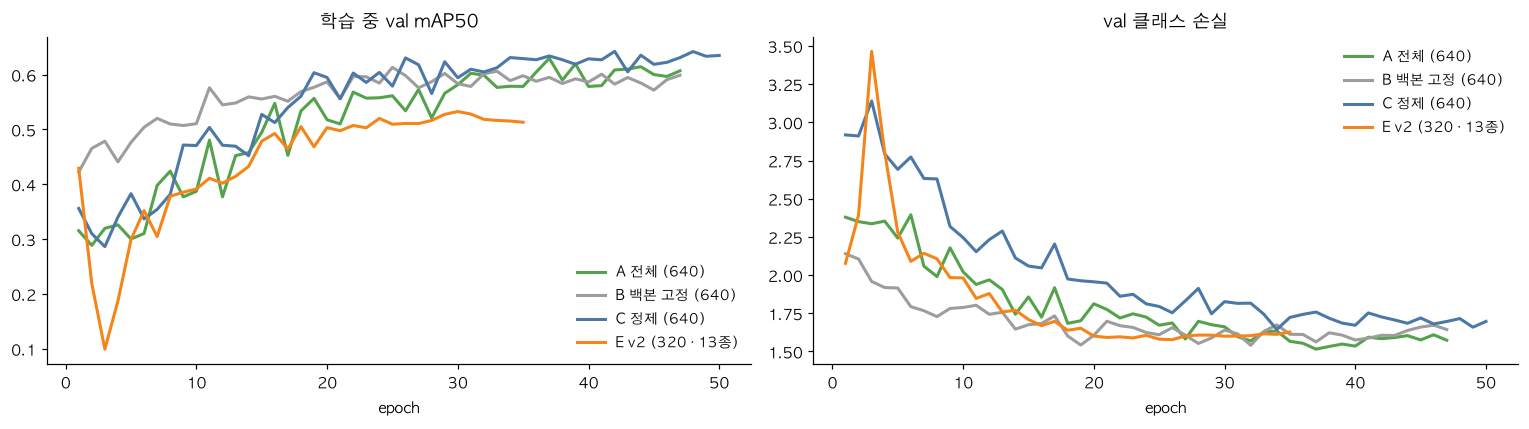

In [11]:
runs = {'A 전체 (640)': 'A_full', 'B 백본 고정 (640)': 'B_freeze10', 'C 정제 (640)': 'C_clean', 'E v2 (320 · 13종)': 'E_v2'}
cols = [COL['app'], COL['gray'], COL['data'], COL['train']]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for (name, d), c in zip(runs.items(), cols):
    df = pd.read_csv(RUNS / d / 'results.csv'); df.columns = df.columns.str.strip()
    ax[0].plot(df.epoch, df['metrics/mAP50(B)'], label=name, c=c, lw=2)
    ax[1].plot(df.epoch, df['val/cls_loss'], label=name, c=c, lw=2)
ax[0].set_title('학습 중 val mAP50', weight='bold'); ax[1].set_title('val 클래스 손실', weight='bold')
for a in ax: a.set_xlabel('epoch'); a.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

<sub>⚠️ 학습 중 val은 실험마다 다르다 — C는 정제한 val, E는 320 크기 · 13종 val. 같은 조건(10종 val · 320)에서 다시 재면 A 0.573 vs E 0.577. E 초반의 급락(0.43 → 0.10)은 이어 학습에 학습률 0.01이 컸던 것으로 보인다.</sub>

### 7.1 기준선 vs A vs B — 튜닝하면 원래 알던 것을 잊나?

| COCO가 원래 아는 4종 | 기준선 | **A** 전체 | B 백본 고정 |
|:--|:-:|:-:|:-:|
| 🖱️ 마우스 | 0.853 | 0.898 | **0.948** |
| ☂️ 우산 | 0.652 | **0.722** | 0.608 |
| 📖 책 | 0.036 | **0.334** | 0.314 |
| 🪥 칫솔 | 0.487 | **0.837** | 0.801 |
| **10종 val mAP50** | – | **0.634** | 0.589 |
| 학습 시간 | – | 1시간 55분 | 1시간 18분 |

> 📌 **잊지 않았다 — 오히려 올랐다.** B는 빠르지만 새 6종을 덜 배운다 → **A를 앱 v1으로.**

### 7.2 쟁점 ③ — "그냥 COCO YOLO 쓰면 안 돼?"

| 미션 통과율 | 마우스 | 우산 | 책 | 칫솔 | **4종 전체** |
|:--|:-:|:-:|:-:|:-:|:-:|
| COCO 그대로 | 0.64 | 0.76 | 0.04 | **0.80** | 0.27 |
| A (튜닝) | **1.00** | **0.80** | **0.56** | 0.67 | **0.65** |

> 📌 원래 아는 물건도 튜닝 뒤 **2배 이상** 잘 통과. 게다가 COCO는 모자 · 문 · 휴지 · 양말 · 신발 · 안경을 아예 모른다.

### 7.3 실험 C — 지저분한 박스를 지우면?

EDA에서 본 묶음 · 아주 작은 박스를 **회색으로 칠해** 안 보이게 하고 학습했다. (라벨만 지우면 그 물체를 '배경'으로 배우므로 칠함)
평가 세트도 깨끗한 버전을 만들어 **모델 × 평가** 2×2로 나눠 쟀다.

| val mAP50 | val 원본 | val 정제 |
|:--|:-:|:-:|
| **A** (원본 학습) | 0.634 | **0.709** |
| **C** (정제 학습) | 0.508 | 0.634 |

| 효과 | 값 | 뜻 |
|:--|:-:|:--|
| 평가 효과 (A: 원본 → 정제) | **+0.075** | 원래 점수 일부는 "평가 라벨이 지저분해서" 깎인 것 |
| 학습 효과 (원본 val: A → C) | **−0.126** | 지우고 학습하면 오히려 손해 (정제 val 기준으로도 −0.075) |

- 오른 클래스: 모자 +0.09 · 문 +0.08 · 신발 +0.08
- 내린 클래스: **책 −0.35** · 휴지 −0.32 · 칫솔 −0.17 — 책은 박스의 75%를 지웠더니 배울 게 너무 적어졌다.

> 📌 **채택 안 함.** 교훈: 나쁜 걸 *지우기*보다 **앱 장면에 맞는 걸 *더하기*** → 실험 E로.

### 7.4 실험 E (v2) — "뭐만 해도 마우스로 나와요"

아이폰에서 써 보니 **리모컨 · 휴대폰을 비춰도 "마우스"** 가 떴다.

| 원인 | 왜 생겼나 | 처방 |
|:--|:--|:--|
| "마우스 아닌 비슷한 것"을 본 적 없음 | 학습 사진에 **미션 물건이 있는 사진만** 있었음 | **하드 네거티브** — 리모컨 · 휴대폰 · 시계 · 손 등 16라벨 1,560장을 *박스 없이* 추가 |
| 학습 장면 ≠ 앱 장면 | 학습은 멀리 · 작게, 앱은 가까이 · 크게 | **앱 장면 crop** — 물건 중심으로 잘라 추가, 학습 크기도 앱과 같은 **320** |
| 모든 클래스에 같은 기준 0.5 | 마우스는 원래 점수가 높게 나오는 클래스 | **클래스별 기준** — 네거티브의 잘못 통과 ≤ 2%가 되는 가장 낮은 기준 |

추가로 **컵 · 텀블러 · 의자**를 넣고, 약한 문 · 신발 · 책은 사진을 1,000장까지 늘렸다.

> ⚖️ **쟁점 ④ 시간 vs 데이터** — 박스마다 crop을 만들었더니 2.8만 장, 1에폭 7분 → 60에폭 7시간. **사진 · 클래스마다 가장 큰 박스 하나**로 줄여 1.3만 장, 35에폭 2.1시간으로 맞췄다.

#### 지금 앱 모델로 직접 판정해 보기

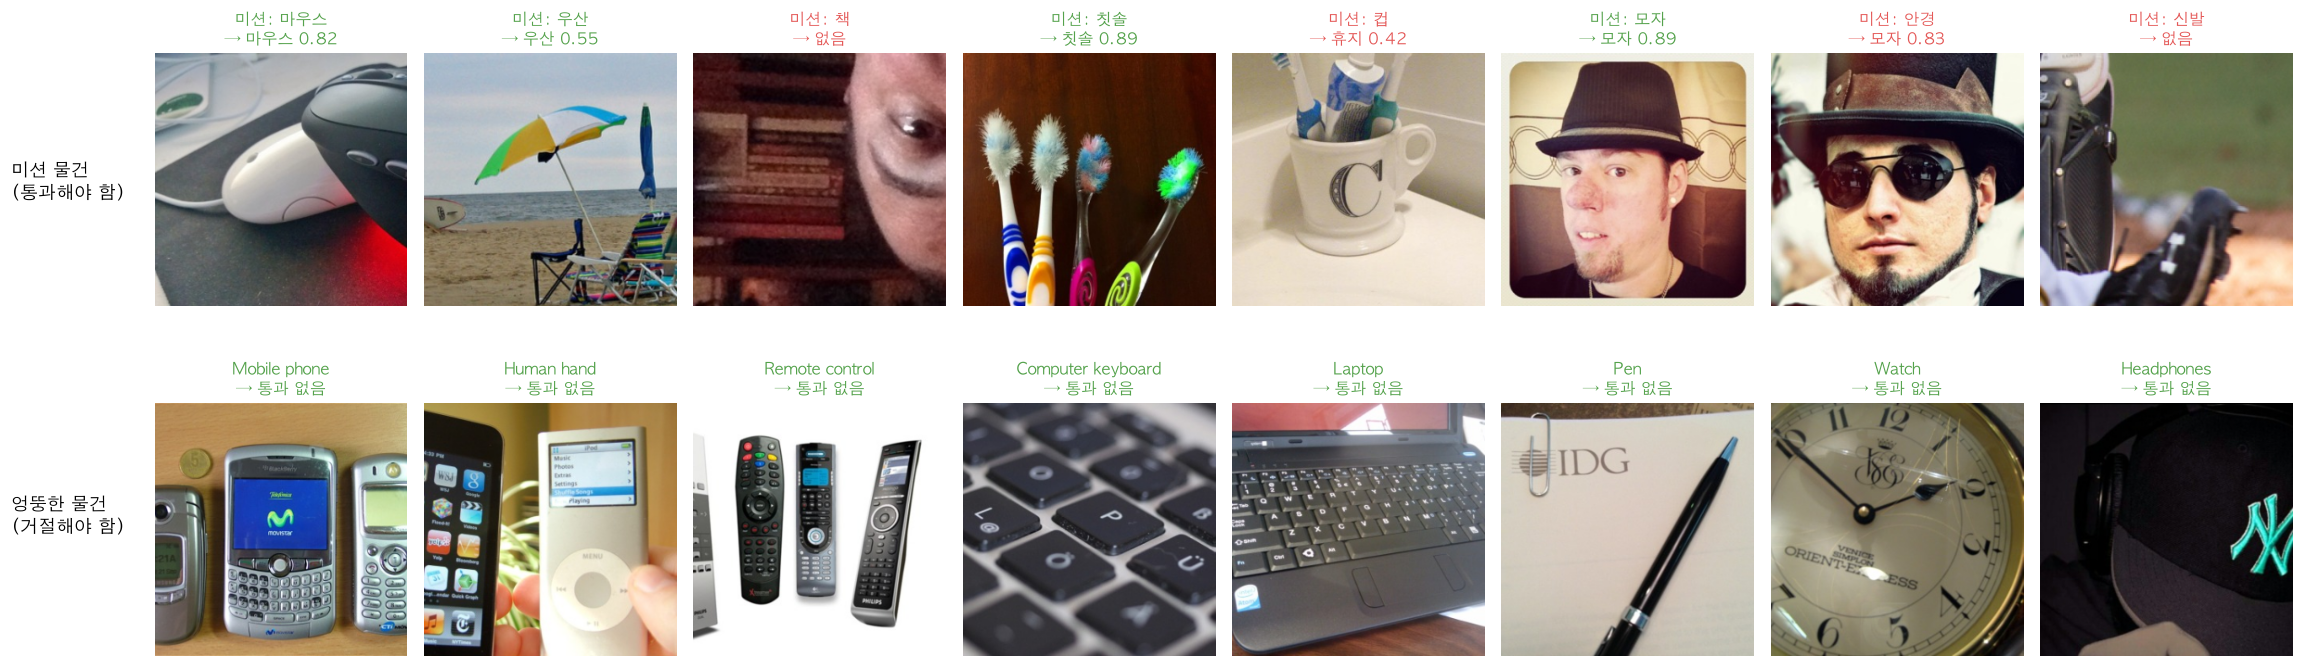

초록 = 맞게 판정, 빨강 = 틀리게 판정


In [12]:
pick_pos = pos[pos.half == 'test'].groupby('target').head(1).head(8)
pick_neg = neg[neg.half == 'test'].groupby('center').head(1).head(8)
fig, axes = plt.subplots(2, 8, figsize=(21, 6.6))
for ax, r in zip(axes[0], pick_pos.itertuples()):
    img = cv2.imread(str(ROOT / 'data/eval13/images/pos' / r.file)); _, _, m = run_app(img)
    ok = m is not None and m['cls'] == r.target
    ax.imshow(cv2.resize(img, (300, 300))[:, :, ::-1]); ax.axis('off')
    got = f"{KO[m['cls']]} {m['score']:.2f}" if m else '없음'
    ax.set_title(f"미션: {KO[r.target]}\n→ {got}", fontsize=10.5,
                 color=COL['app'] if ok else COL['eval'], weight='bold')
for ax, r in zip(axes[1], pick_neg.itertuples()):
    img = cv2.imread(str(ROOT / 'data/eval13/images/neg' / r.file)); _, _, m = run_app(img)
    ax.imshow(cv2.resize(img, (300, 300))[:, :, ::-1]); ax.axis('off')
    ax.set_title(f"{r.center}\n→ {'잘못 통과: ' + KO[m['cls']] if m else '통과 없음'}", fontsize=10.5,
                 color=COL['eval'] if m else COL['app'], weight='bold')
fig.text(0.005, 0.73, '미션 물건\n(통과해야 함)', fontsize=12, weight='bold', va='center')
fig.text(0.005, 0.27, '엉뚱한 물건\n(거절해야 함)', fontsize=12, weight='bold', va='center')
plt.tight_layout(rect=(0.06, 0, 1, 1), h_pad=2.5); plt.show()
print('초록 = 맞게 판정, 빨강 = 틀리게 판정')

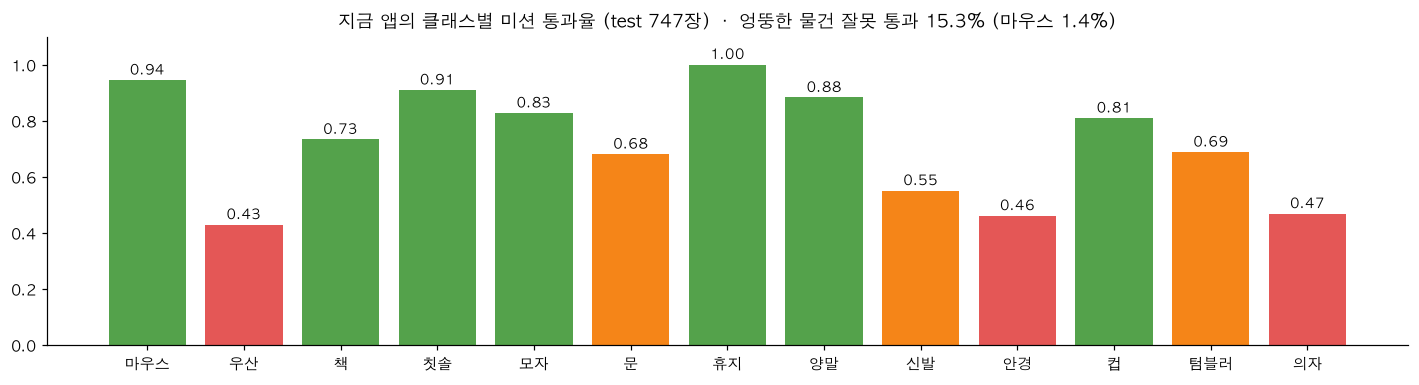

초록 ≥ 0.7 · 주황 ≥ 0.5 · 빨강 < 0.5   (휴지는 test 사진이 1장뿐이라 숫자를 믿기 어렵다)


In [13]:
# 저장된 평가 사진 test 절반 전체를 지금 앱 모델로 다시 판정 (CPU 10초 안팎)
def judge(df, sub):
    out = []
    for r in df.itertuples():
        _, _, m = run_app(cv2.imread(str(ROOT / 'data/eval13/images' / sub / r.file)))
        out.append(-1 if m is None else m['cls'])
    return np.array(out)

pos_t, neg_t = pos[pos.half == 'test'].reset_index(drop=True), neg[neg.half == 'test'].reset_index(drop=True)
pos_t['pred'], neg_t['pred'] = judge(pos_t, 'pos'), judge(neg_t, 'neg')
pass_rate = pos_t.assign(ok=pos_t.pred == pos_t.target).groupby('target').ok.mean().rename(index=dict(enumerate(KO)))
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(pass_rate.index, pass_rate.values, color=[COL['app'] if v >= .7 else (COL['train'] if v >= .5 else COL['eval']) for v in pass_rate.values])
for i, v in enumerate(pass_rate.values): ax.text(i, v + .02, f'{v:.2f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.1); ax.set_title(f'지금 앱의 클래스별 미션 통과율 (test {len(pos_t)}장)  ·  '
                                  f'엉뚱한 물건 잘못 통과 {np.mean(neg_t.pred >= 0):.1%} (마우스 {np.mean(neg_t.pred == 0):.1%})', weight='bold')
plt.tight_layout(); plt.show()
print('초록 ≥ 0.7 · 주황 ≥ 0.5 · 빨강 < 0.5   (휴지는 test 사진이 1장뿐이라 숫자를 믿기 어렵다)')

#### A vs E 비교 (`wakeup_v2.ipynb`)

**① 엉뚱한 물건 422장이 통과된 비율** (기준 0.5)

| | A (v1) | **E (v2)** |
|:--|:-:|:-:|
| "마우스"로 통과 | 9.2% | **0.9%** |
| 아무 미션으로든 통과 | 22.3% | **11.4%** |

<sub>A가 마우스로 착각한 것: 리모컨의 62%, 휴대폰 29%, 시계 23%, 헤드폰 16% — *"손에 쥐는 작고 매끈한 것 = 마우스"* 로 배웠던 것.</sub>

**② 미션 통과율** (기준 0.5)

| | 마우스 | 우산 | 책 | 칫솔 | 모자 | 문 | 양말 | 신발 | 안경 | **기존 10종** |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| A | **1.00** | **0.76** | 0.64 | 0.56 | 0.76 | 0.27 | 0.76 | 0.35 | **0.68** | 0.62 |
| E | 0.96 | 0.59 | **0.83** | **0.61** | **0.81** | **0.59** | 0.76 | **0.50** | 0.51 | **0.72** |

<sub>새 3종(E): 컵 0.82 · 텀블러 0.66 · 의자 0.44. 휴지는 평가 사진이 3장뿐이라 표에서 뺐다.</sub>

**③ 클래스별 기준까지 넣은 최종 비교** (test 절반)

| 설정 | 기존 10종 통과율 | 잘못 통과 (아무거나) | 잘못 통과 (마우스) |
|:--|:-:|:-:|:-:|
| A · 기준 0.5 &nbsp;<sub>(앱 v1)</sub> | 0.617 | 22.0% | 10.0% |
| A · 클래스별 기준 | 0.631 | **12.4%** | 1.4% |
| E · 기준 0.5 | **0.722** | 15.3% | 1.0% |
| **E · 클래스별 기준** &nbsp;<sub>(앱 v2)</sub> | 0.696 | 15.3% | 1.4% |

> ⚖️ **쟁점 ⑤ 모델 덕인가, 기준 덕인가?**
> - **A에 기준만 클래스별로 바꿔도** 마우스 잘못 통과 10.0% → 1.4%. *기준 조정만으로도 상당 부분 해결된다.*
> - 그래도 E는 비슷한 잘못 통과에서 통과율이 **+0.065** 높다 → 네거티브 학습은 *기준을 높이지 않고도* 구분하게 해 준다.
>
> 🔒 **교체 규칙은 실험 *전에* 정했다** — "잘못 통과가 줄고, 기존 10종 통과율이 0.05보다 많이 떨어지지 않으면 교체". 결과를 보고 규칙을 정하면 원하는 결론에 맞추게 된다.

**④ 약한 클래스(문 · 신발 · 책)의 F1**

| | 앱 장면 F1 &nbsp;A → E | 전체 사진 F1 &nbsp;A → E |
|:--|:-:|:-:|
| 🚪 문 | 0.50 → **0.79** | 0.31 → **0.42** |
| 👟 신발 | 0.45 → **0.68** | 0.39 → <span style="color:#E45756">**0.27**</span> |
| 📖 책 | 0.76 → **0.82** | 0.36 → 0.35 |

> 📌 앱 장면에선 셋 다 올랐지만 전체 사진에선 신발이 내렸다. **앱 장면에 맞춰 학습했으니 앱 장면에서 좋아진 것** — 무엇에 맞출지를 고른 결과다.

---

## 8. 앱으로 만들기

> 💡 **한 줄** — 서버 없이 **링크 하나로** 누구나 아이폰에서 돌려 볼 수 있는 웹앱.

### 8.1 쟁점 ⑥ — 아이폰에서 어떻게 돌리나

| 방법 | 👍 | 👎 | |
|:--|:--|:--|:-:|
| 네이티브 iOS (CoreML) | 가장 빠름, 진짜 OS 알람 | Xcode · 개발자 계정 필요, 스터디원이 못 돌려 봄 | ✗ |
| 서버 추론 (Flask + GPU) | 큰 모델 가능 | 서버 비용 · 관리, 매 프레임 업로드 지연 | ✗ |
| **웹앱 + 브라우저 추론**<br><sub>onnxruntime-web</sub> | 링크 하나로 실행, 서버 없음 (GitHub Pages 무료)<br>사진이 폰 밖으로 안 나감 | 화면을 켜 둬야 알람이 울림 (웹 제약)<br>네이티브보다 느림 | ✅ |

### 8.2 구성 (`docs/`, 프레임워크 없음)

| 파일 | 역할 |
|:--|:--|
| `index.html` · `style.css` · `app.js` | 화면 · 카메라 · 알람 · 판정 루프 |
| `postprocess.js` | decode · NMS · 주인공 고르기 · 연속 판정 — **파이썬과 같은 동작** (node 테스트) |
| `classes.js` | 13종 이름 · 이모지 · **클래스별 기준** (`src/config.py`에서 생성) |
| `model.onnx` | 10.5MB, 출력 [1, 17, 2100] |

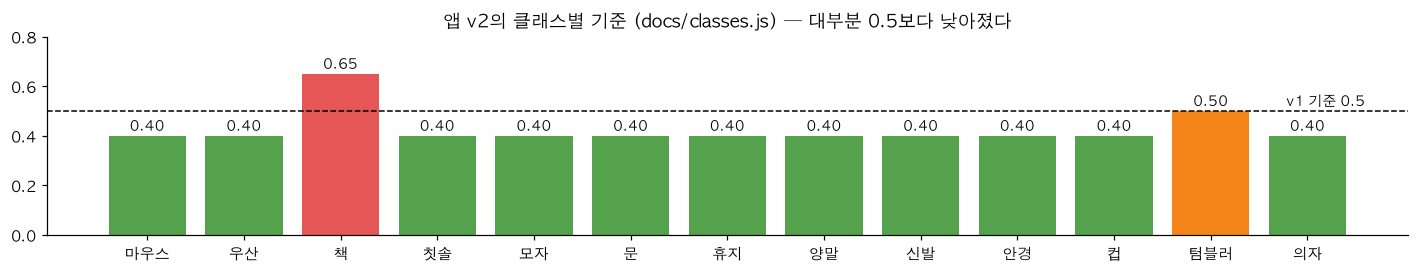

In [14]:
cf = pd.Series(app_conf).rename(index=dict(enumerate(KO)))
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.bar(cf.index, cf.values, color=[COL['eval'] if v > 0.5 else (COL['train'] if v == 0.5 else COL['app']) for v in cf.values])
ax.axhline(0.5, ls='--', c='k', lw=1); ax.text(12.6, 0.52, 'v1 기준 0.5', ha='right', fontsize=9)
for i, v in enumerate(cf.values): ax.text(i, v + .02, f'{v:.2f}', ha='center', fontsize=9)
ax.set_ylim(0, 0.8); ax.set_title('앱 v2의 클래스별 기준 (docs/classes.js) — 대부분 0.5보다 낮아졌다', weight='bold')
plt.tight_layout(); plt.show()

<sub>네거티브를 학습해 엉뚱한 물건의 점수가 낮아졌으므로, 기준을 **낮춰도** 잘못 통과 ≤ 2%를 지킨다. 책만 0.65로 올랐다 (책장·종이류를 책으로 잡는 경향).</sub>

### 8.3 폰에서 돌려 봐야 알게 된 문제들

| 증상 | 원인 | 해결 |
|:--|:--|:--|
| 스캔 틀이 화면 밖으로 밀림 | 카메라는 가로 영상, 화면은 세로 (`object-fit: cover`로 잘림) | **화면에 보이는 영역** 기준으로 틀 계산 |
| 무음 모드에서 알람 소리 안 남 | iOS 무음 스위치 | `audioSession.type = 'playback'` + 탭할 때 오디오 깨우기 |
| 칫솔 · 안경 같은 얇은 물건이 통과 못 함 | 규칙이 "박스 면적 ≥ 틀의 15%" | **"긴 변 ≥ 틀의 40%"** 로 변경 |
| 한두 프레임 놓치면 진행 바가 0으로 | 0.5초 연속 판정이 너무 엄격 | 프레임 시간 기반 **유예(grace)** |
| 우산 미션에 모자 → *"그건 모자가 아니잖아요!"* | 문구에 잡힌 물건 이름을 넣음 | *"그건 우산이 아니라 모자예요!"* (받침 따라 이/가) |
| 화면이 꺼짐 | 자동 잠금 | Wake Lock API |

<details>
<summary><b>판정 루프 코드 보기</b> (docs/app.js 발췌)</summary>

```javascript
const out  = await session.run({ [session.inputNames[0]]: toTensor() });   // 스캔 틀 → 320×320 텐서
const dets = applyConf(nms(decode(o.data, ch - 4, n, DECODE_CONF, INPUT), IOU), CLASSES, CONF);
const main = pickMain(dets, INPUT, MIN_SIDE);                               // 긴 변 ≥ 40% 중 가장 큰 박스
const grace = Math.max(GRACE_MS, 2.5 * avgFrameMs);                         // 느린 폰도 한 프레임은 놓쳐도 됨
const progress = streak.update(main && main.cls === mission.id, now, grace); // 0.5초 연속이면 1.0 → 알람 해제
```
</details>

---

## 9. 결론 · 한계 · 다음 할 일

### 9.1 결론

> **COCO YOLO11n을 Open Images 13종으로 파인튜닝**하고, **하드 네거티브 + 앱 장면 crop + 클래스별 기준**으로
> "뭐든 마우스" 잘못 통과를 **9.2% → 0.9%**, 미션 통과율을 **0.62 → 0.70** 으로 바꿔 아이폰 웹앱에 올렸다.

| 배운 것 | 근거 |
|:--|:--|
| 사전학습 모델도 **튜닝하면 원래 알던 것까지** 좋아진다 | 기준선 → A: 책 0.04 → 0.56 (통과율) |
| 성능이 낮은 이유는 **양보다 질** | 박스 최다인 책 · 신발이 최하위 |
| 나쁜 데이터 *지우기*보다 **맞는 데이터 *더하기*** | C 학습 효과 −0.126, E는 통과율 +0.10 |
| **지표는 쓰임새에 맞춰** 골라야 한다 | 신발: 앱 장면 F1 ↑, 전체 사진 F1 ↓ |
| **기준값 조정**은 싸고 강력하다 | A에 기준만 바꿔도 마우스 잘못 통과 10.0% → 1.4% |

### 9.2 한계

- 모든 숫자는 **Open Images 사진을 잘라서** 잰 것 — 실제 폰 카메라(흔들림 · 조명 · 초점)와 다르다. 직접 찍은 사진 테스트가 아직 없다.
- 평가 사진이 적은 클래스: 휴지 3장 · 칫솔 18장 · 마우스 23장 · 양말 25장 → 몇 장에 크게 흔들린다.
- **휴지** = Open Images의 *Toilet paper*(두루마리)뿐. 각티슈 · 물티슈는 배운 적 없다.
- **텀블러** = 실제로는 *Bottle*(물병) 라벨. 우산 · 안경은 v2에서 내렸고, 의자는 0.44로 약하다.

### 9.3 다음 할 일

| 우선 | 할 일 | 기대 |
|:-:|:--|:--|
| 1 | 직접 찍은 사진 클래스당 10~20장 (`my_photos/`) | 진짜 통과율 |
| 2 | 휴지에 *Facial tissue holder*(각티슈) · *Paper towel*(키친타올) 합치기 | 한국식 '휴지' |
| 3 | 우산 · 안경 · 의자 앱 장면 crop 보강 | v2에서 내린 클래스 회복 |
| 4 | 이어 학습 학습률 낮추기 (`lr0=0.001`) | 초반 급락 방지 |

---

## 10. 토론 질문

1. **분류 vs 탐지** — 이 앱을 ResNet 분류기로 만든다면 "빈 벽"이나 "엉뚱한 물건"을 어떻게 처리할 수 있을까?
   <sub>힌트: "기타" 클래스, 확률 기준, sigmoid</sub>
2. **불균형** — 박스가 가장 많은 책이 가장 못했다. 클래스 가중치 · 오버샘플링은 언제 효과가 있을까?
3. **지우기 vs 더하기** — 지저분한 라벨을 *지우는* 것과 맞는 데이터를 *더하는* 것, 각각 언제 맞을까?
4. **지표** — 신발의 전체 사진 F1은 내렸는데 앱 통과율은 올랐다. "모델이 좋아졌다"는 무엇으로 말해야 할까?
5. **기준 vs 재학습** — 기준 조정만으로 "뭐든 마우스"의 대부분이 해결됐다. 재학습은 언제 꼭 필요할까?
6. **사전 규칙** — 모델 교체 규칙을 왜 결과를 보기 *전에* 정해야 할까?
7. **확장** — 리모컨 미션을 추가한다면? 지금 리모컨은 네거티브인데 무엇을 바꿔야 할까?

---

<div align="center"><sub>ROKEY 부트캠프 딥러닝 스터디 · 코드와 앱: github.com/rltjr4362/wakeup-mission</sub></div>